# 09 — Multimodal QA input with page citations

## Objective

Render the same retrieved physical page used by the text-only condition, inspect the image, and construct a provider-neutral multimodal message description without sending an API request.

## Concept

A controlled text-versus-image comparison must keep the document, question, retrieved page numbers, prompt contract, temperature, and preferably model family fixed. Only the evidence representation should change: extracted text versus rendered pixels.

In [1]:
import base64
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import pymupdf
from PIL import Image


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
SLIDES_PDF = PROJECT_ROOT / "data" / "documents" / "ch2.pdf"
MODEL_PROVIDER = None
MODEL_NAME = None
RENDER_DPI = 144

## Implementation — render one retrieved page

At 144 dpi, one PDF point maps to two image pixels because $144/72=2$. The exact PNG bytes are retained in memory and never printed.

In [2]:
retrieved_page_numbers = [49]
with pymupdf.open(SLIDES_PDF) as document:
    page = document[retrieved_page_numbers[0] - 1]
    page_rect = page.rect
    pixmap = page.get_pixmap(dpi=RENDER_DPI, alpha=False)
    page_png = pixmap.tobytes("png")

render_summary = {
    "physical_page": retrieved_page_numbers[0],
    "dpi": RENDER_DPI,
    "pdf_dimensions_points": (round(page_rect.width, 2), round(page_rect.height, 2)),
    "image_dimensions_pixels": (pixmap.width, pixmap.height),
    "png_bytes": len(page_png),
}
render_summary

{'physical_page': 49,
 'dpi': 144,
 'pdf_dimensions_points': (362.83, 272.13),
 'image_dimensions_pixels': (726, 545),
 'png_bytes': 78934}

## Inspection — view the exact model input image

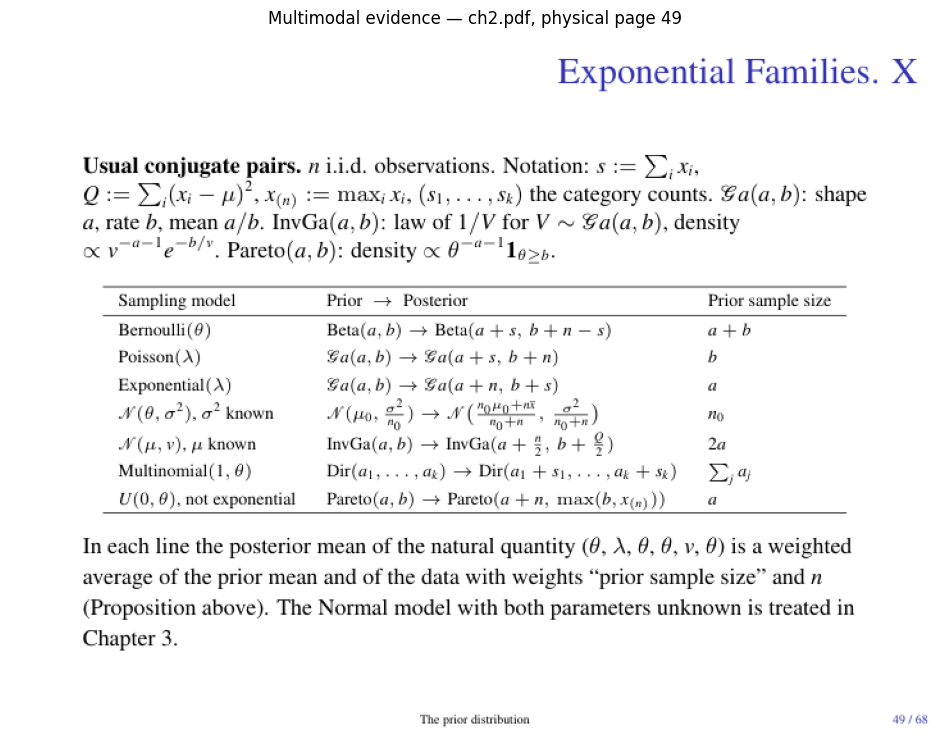

In [3]:
page_image = Image.open(BytesIO(page_png))
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.imshow(page_image)
ax.set_title("Multimodal evidence — ch2.pdf, physical page 49")
ax.axis("off")
plt.tight_layout()
plt.show()

## Implementation — describe the multimodal message

The payload is provider-neutral on purpose. A later experiment can translate this structure into the chosen SDK after the provider and model version are recorded.

In [4]:
question = "Which physical page contains the table titled 'Usual conjugate pairs'?"
image_base64 = base64.b64encode(page_png).decode("ascii")

multimodal_message = {
    "instruction": (
        "Answer only from the supplied page image. Cite every factual claim using [Page N]. "
        "If the evidence is insufficient, say so instead of guessing."
    ),
    "question": question,
    "evidence": [
        {
            "page_number": 49,
            "media_type": "image/png",
            "image_base64": image_base64,
        }
    ],
}

payload_summary = {
    "question": multimodal_message["question"],
    "evidence_pages": [item["page_number"] for item in multimodal_message["evidence"]],
    "media_types": [item["media_type"] for item in multimodal_message["evidence"]],
    "base64_characters": len(image_base64),
    "model_provider_configured": MODEL_PROVIDER is not None and MODEL_NAME is not None,
}
payload_summary

{'question': "Which physical page contains the table titled 'Usual conjugate pairs'?",
 'evidence_pages': [49],
 'media_types': ['image/png'],
 'base64_characters': 105248,
 'model_provider_configured': False}

## Interpretation

The model would see table geometry, mathematical symbols, and surrounding layout that may be damaged by text extraction. The trade-off is higher input size, latency, and cost. Rendering resolution is therefore an experimental parameter, not an invisible implementation detail.

## Validation

In [5]:
assert page_png.startswith(b"\x89PNG")
assert page_image.size == (pixmap.width, pixmap.height)
assert multimodal_message["evidence"][0]["page_number"] == retrieved_page_numbers[0]
assert multimodal_message["evidence"][0]["media_type"] == "image/png"
assert base64.b64decode(image_base64) == page_png

print("Rendered evidence and message metadata are internally consistent.")

Rendered evidence and message metadata are internally consistent.


## Next step

`10_controlled_evaluation.ipynb` defines the four experimental conditions and demonstrates scoring on synthetic wiring data that is visibly separated from real project results.